# Task 5 · Sales Prediction Using Python

**Objective:** Build a regression model that predicts product sales from advertising spend on three media channels: **TV, Radio and Newspaper**.

**Dataset:** the *Advertising* dataset (from *An Introduction to Statistical Learning*). It has 200 markets, with ad spend in \$ thousands for each channel and the resulting sales in thousand units. File: `Advertising.csv` (keep it in the same folder as this notebook).

**Tech stack:** Python, pandas, scikit-learn, matplotlib, seaborn.

**Steps**
1. Load the data and run EDA (null check, descriptive statistics, pairplot)
2. Individual scatter plots: Sales vs TV, Radio and Newspaper
3. Correlation matrix heatmap
4. Train/test split
5. Baseline Linear Regression model

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# One colour for the data, one neutral for reference lines, one warm colour for the negative side of the heatmap
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c4",
    "axes.labelcolor": MUTED,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
})

## 2. Load the data and basic EDA

In [2]:
df = pd.read_csv("Advertising.csv")

# The first column is only a row index saved by R, so we drop it
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (200, 4)

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


### 2.1 Null check

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())

Missing values per column:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Total missing values: 0
Duplicate rows      : 0


### 2.2 Descriptive statistics

In [5]:
df.describe().round(2)

,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


### 2.3 Pairplot of all features

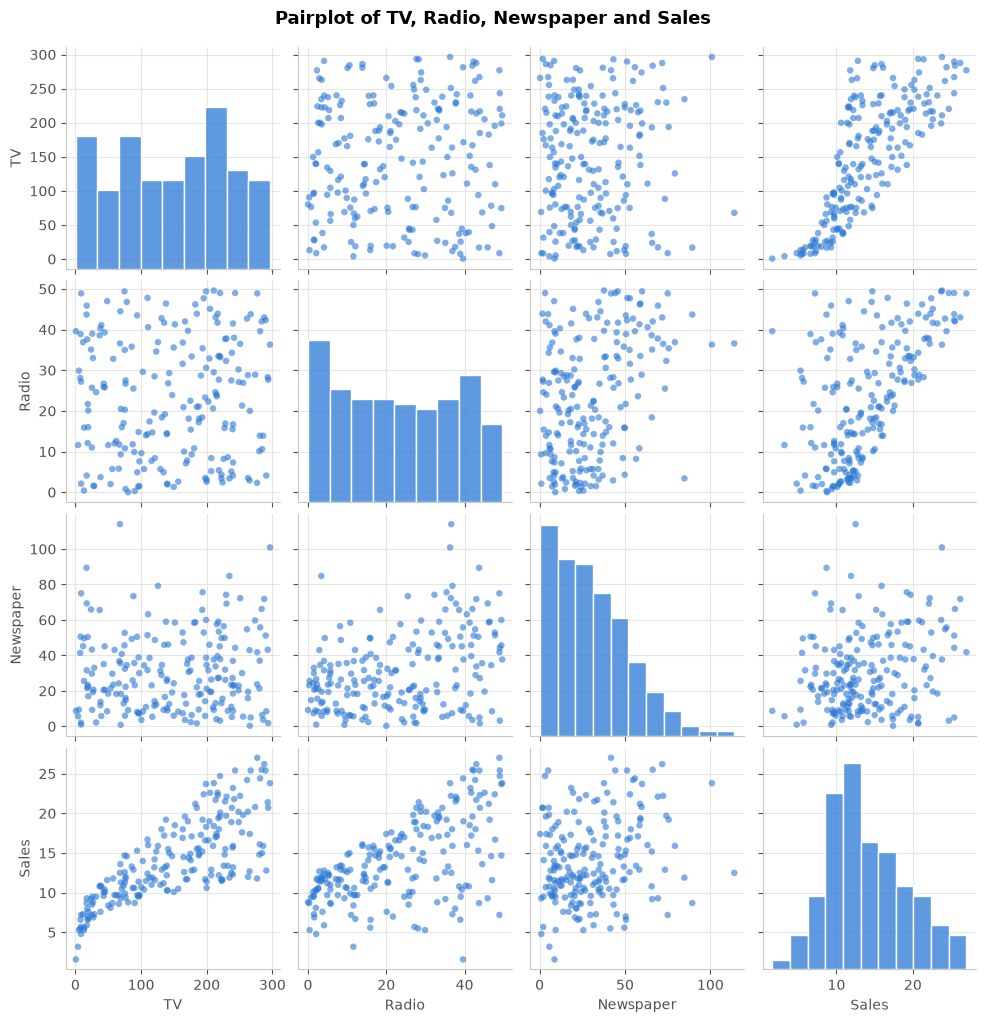

In [6]:
g = sns.pairplot(
    df,
    diag_kind="hist",
    plot_kws={"color": BLUE, "alpha": 0.6, "s": 22, "edgecolor": "none"},
    diag_kws={"color": BLUE, "edgecolor": "white"},
)
g.fig.suptitle("Pairplot of TV, Radio, Newspaper and Sales", y=1.02, fontsize=13, fontweight="bold")
plt.show()

**What we see**
- The data has 200 rows and 4 numeric columns, with **no missing values and no duplicate rows**, so no cleaning is needed.
- Average spend is about \$147k on TV, \$23k on Radio and \$31k on Newspaper, and average sales are about 14 thousand units.
- Newspaper spend is right-skewed: the median is about \$26k but a few markets go up to \$114k.
- In the pairplot, Sales rises clearly with TV and Radio spend. The three spend columns do not look strongly related to each other.

## 3. Individual scatter plots: Sales vs each advertising channel

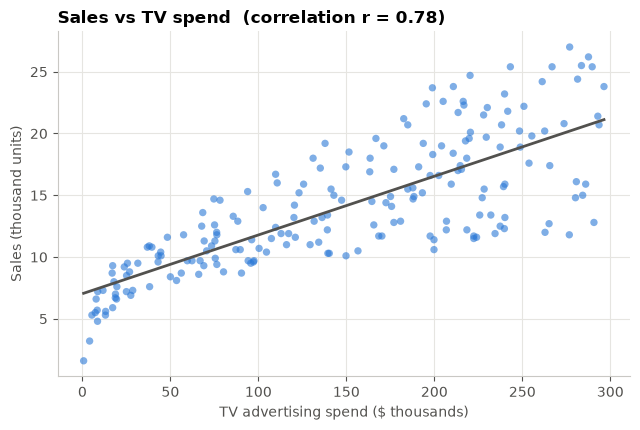

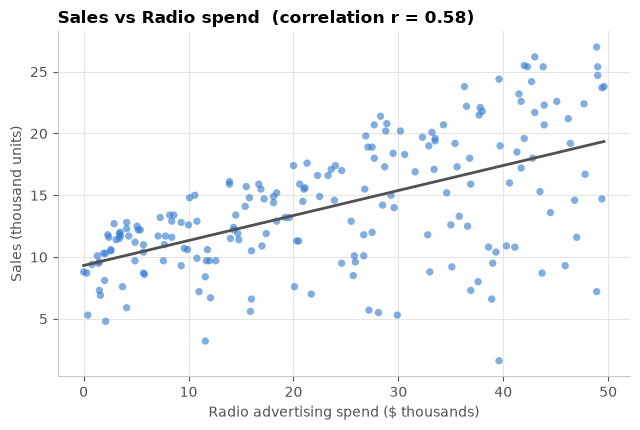

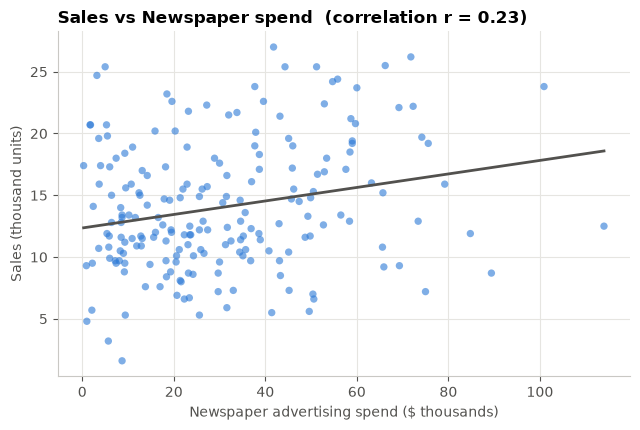

In [7]:
features = ["TV", "Radio", "Newspaper"]

for col in features:
    r = df[col].corr(df["Sales"])
    fig, ax = plt.subplots(figsize=(6.5, 4.4))
    sns.regplot(
        data=df, x=col, y="Sales", ax=ax, ci=None,
        scatter_kws={"color": BLUE, "alpha": 0.6, "s": 28, "edgecolor": "none"},
        line_kws={"color": MUTED, "linewidth": 2},
    )
    ax.set_title(f"Sales vs {col} spend  (correlation r = {r:.2f})")
    ax.set_xlabel(f"{col} advertising spend ($ thousands)")
    ax.set_ylabel("Sales (thousand units)")
    plt.tight_layout()
    plt.show()

**What we see**
- **TV:** the strongest and most linear relationship (r = 0.78). At very high TV spend the points spread out more, so sales are less predictable there.
- **Radio:** a moderate positive relationship (r = 0.58) with a lot of spread, especially at high Radio spend.
- **Newspaper:** a weak relationship (r = 0.23); the points form a shapeless cloud, so Newspaper spend tells us little about sales on its own.

## 4. Correlation matrix heatmap

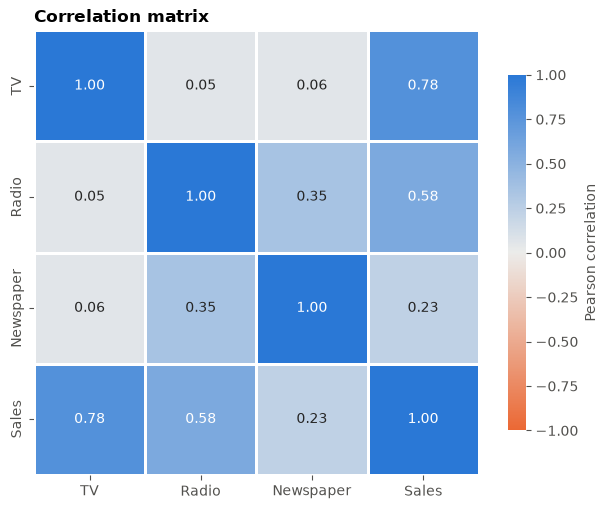

In [8]:
corr = df.corr()

# Blue = positive correlation, orange = negative, light grey = none
cmap = LinearSegmentedColormap.from_list("blue_orange", [ORANGE, "#ececea", BLUE])

plt.figure(figsize=(6.5, 5.2))
ax = sns.heatmap(
    corr, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1,
    linewidths=2, linecolor="white", square=True,
    cbar_kws={"label": "Pearson correlation", "shrink": 0.8},
)
ax.grid(False)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

In [9]:
print("Correlation of each feature with Sales:")
print(corr["Sales"].drop("Sales").sort_values(ascending=False).round(3))

Correlation of each feature with Sales:
TV           0.782
Radio        0.576
Newspaper    0.228
Name: Sales, dtype: float64


**What we see**
- Sales is most correlated with **TV (0.78)**, then **Radio (0.58)**, then **Newspaper (0.23)**.
- The features are only weakly correlated with each other (TV-Radio 0.05, TV-Newspaper 0.06, Radio-Newspaper 0.35), so multicollinearity should not be a serious problem for Linear Regression here.

## 5. Train/test split

In [10]:
X = df[["TV", "Radio", "Newspaper"]]   # features
y = df["Sales"]                         # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape, "->", len(X_train), "rows (80%)")
print("Test set    :", X_test.shape, "->", len(X_test), "rows (20%)")

Training set: (160, 3) -> 160 rows (80%)
Test set    : (40, 3) -> 40 rows (20%)


## 6. Baseline model: Linear Regression

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", round(model.intercept_, 4))
pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_}).round(4)

Intercept: 2.9791


,Feature,Coefficient
0,TV,0.0447
1,Radio,0.1892
2,Newspaper,0.0028


In [12]:
def evaluate(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R²": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
    }

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

results = pd.DataFrame({
    "Train": evaluate(y_train, y_train_pred),
    "Test": evaluate(y_test, y_test_pred),
}).round(4)
results

,Train,Test
R²,0.8957,0.8994
MAE,1.1985,1.4608
MSE,2.7051,3.1741
RMSE,1.6447,1.7816


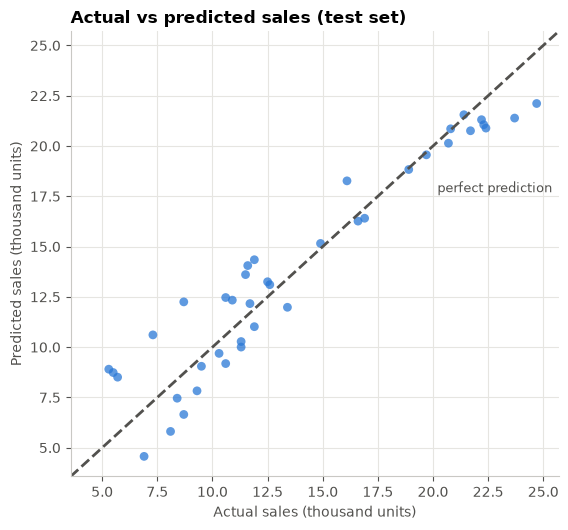

In [13]:
fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.scatter(y_test, y_test_pred, color=BLUE, alpha=0.75, s=40, edgecolor="none")

lims = [min(y_test.min(), y_test_pred.min()) - 1, max(y_test.max(), y_test_pred.max()) + 1]
ax.plot(lims, lims, color=MUTED, linewidth=2, linestyle="--")
ax.text(lims[1] - 0.3, lims[1] - 8, "perfect prediction", color=MUTED, ha="right", fontsize=9)

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Actual sales (thousand units)")
ax.set_ylabel("Predicted sales (thousand units)")
ax.set_title("Actual vs predicted sales (test set)")
plt.tight_layout()
plt.show()

In [14]:
pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred.round(2),
    "Error": (y_test.values - y_test_pred).round(2),
}).head(10)

,Actual,Predicted,Error
0,16.9,16.41,0.49
1,22.4,20.89,1.51
2,21.4,21.55,-0.15
3,7.3,10.61,-3.31
4,24.7,22.11,2.59
5,12.6,13.11,-0.51
6,22.3,21.06,1.24
7,8.4,7.46,0.94
8,11.5,13.61,-2.11
9,14.9,15.16,-0.26


**How to read the results**
- Spend is in \$ thousands and sales in thousand units. Holding the other channels fixed, an extra \$1k on **TV** adds about 0.045 thousand units (roughly 45 units) and an extra \$1k on **Radio** adds about 0.189 thousand units (roughly 189 units). The **Newspaper** coefficient (about 0.003) is close to zero.
- On the test set the baseline model reaches **R² ≈ 0.90**, with an average error (MAE) of about 1.46 and RMSE of about 1.78 thousand units, against average sales of about 14.0.
- Train and test scores are very close (R² 0.896 vs 0.899), so the model is **not overfitting**. The test set has only 40 rows, so these numbers will move a little with a different random split.
- In the actual-vs-predicted plot most points sit near the dashed line. The model tends to over-predict some low-sales markets (actual 5-9, predicted 9-12) and under-predict some of the highest ones, which fits the spread seen in the TV scatter plot.

## 7. Conclusion

- A plain Linear Regression on TV, Radio and Newspaper spend explains about **90% of the variance in sales** on unseen data (test R² ≈ 0.90, RMSE ≈ 1.78 thousand units), which makes a solid baseline.
- **TV** is the strongest driver of sales overall, and **Radio** brings the most extra sales per dollar spent. **Newspaper** adds very little.
- **Possible next steps:** use cross-validation for a more stable score, test whether dropping Newspaper changes the result, try interaction or polynomial features (for example TV × Radio), and compare against tree-based models such as Random Forest.